Loading EMNIST with max_train=None, max_test=None
Train shape: (88800, 28, 28, 1, 1), Test shape: (14800, 28, 28, 1, 1)
Starting NOC training...
Initializing 4 agents with 2500 samples each...
Training initial agent 1/4...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training initial agent 2/4...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training initial agent 3/4...
Training initial agent 4/4...
Processing batch 10, samples 11800-12000/88800
Processing batch 20, samples 13800-14000/88800
Processing batch 30, samples 15800-16000/88800
Processing batch 40, samples 17800-18000/88800
Processing batch 50, samples 19800-20000/88800
Processing batch 60, samples 21800-22000/88800
Processing batch 70, samples 23800-24000/88800
Processing batch 80, samples 25800-26000/88800
Processing batch 90, samples 27800-28000/88800
Processing batch 100, samples 29800-30000/88800
Processing batch 110, samples 31800-32000/88800
Processing batch 120, samples 33800-34000/88800
Processing batch 130, samples 35800-36000/88800
Processing batch 140, samples 37800-38000/88800
Processing batch 150, samples 39800-40000/88800
Processing batch 160, samples 41800-42000/88800
Processing batch 170, samples 43800-44000/88800
Processing batch 180, samples 45800-46000/88800
Processing batch 190, samples 47800-48000/88800
Processing batch 200, samples 49800-5

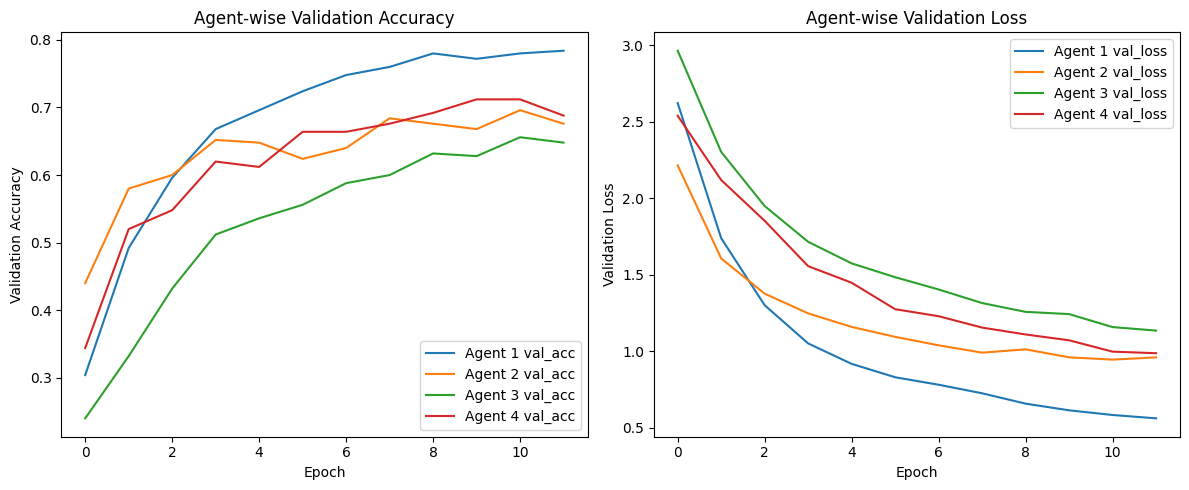

Agent 1 Train Accuracy: 0.7890 | Test Accuracy: 0.7646
Agent 2 Train Accuracy: 0.7158 | Test Accuracy: 0.6866
Agent 3 Train Accuracy: 0.6807 | Test Accuracy: 0.6630
Agent 4 Train Accuracy: 0.7118 | Test Accuracy: 0.6870


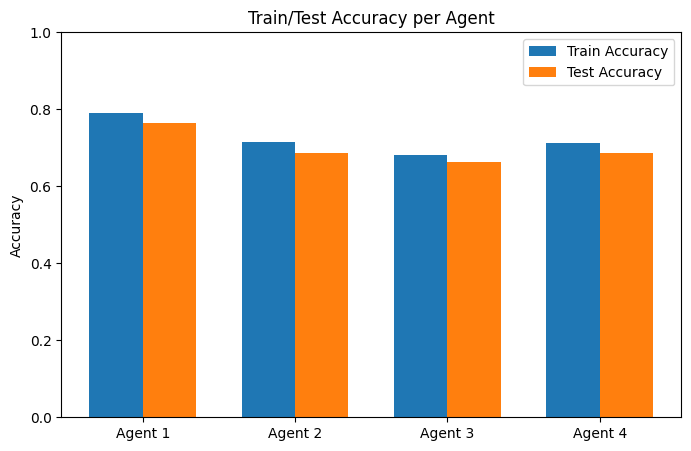

NOC-based Multi-Agent Test Accuracy: 0.763445945945946


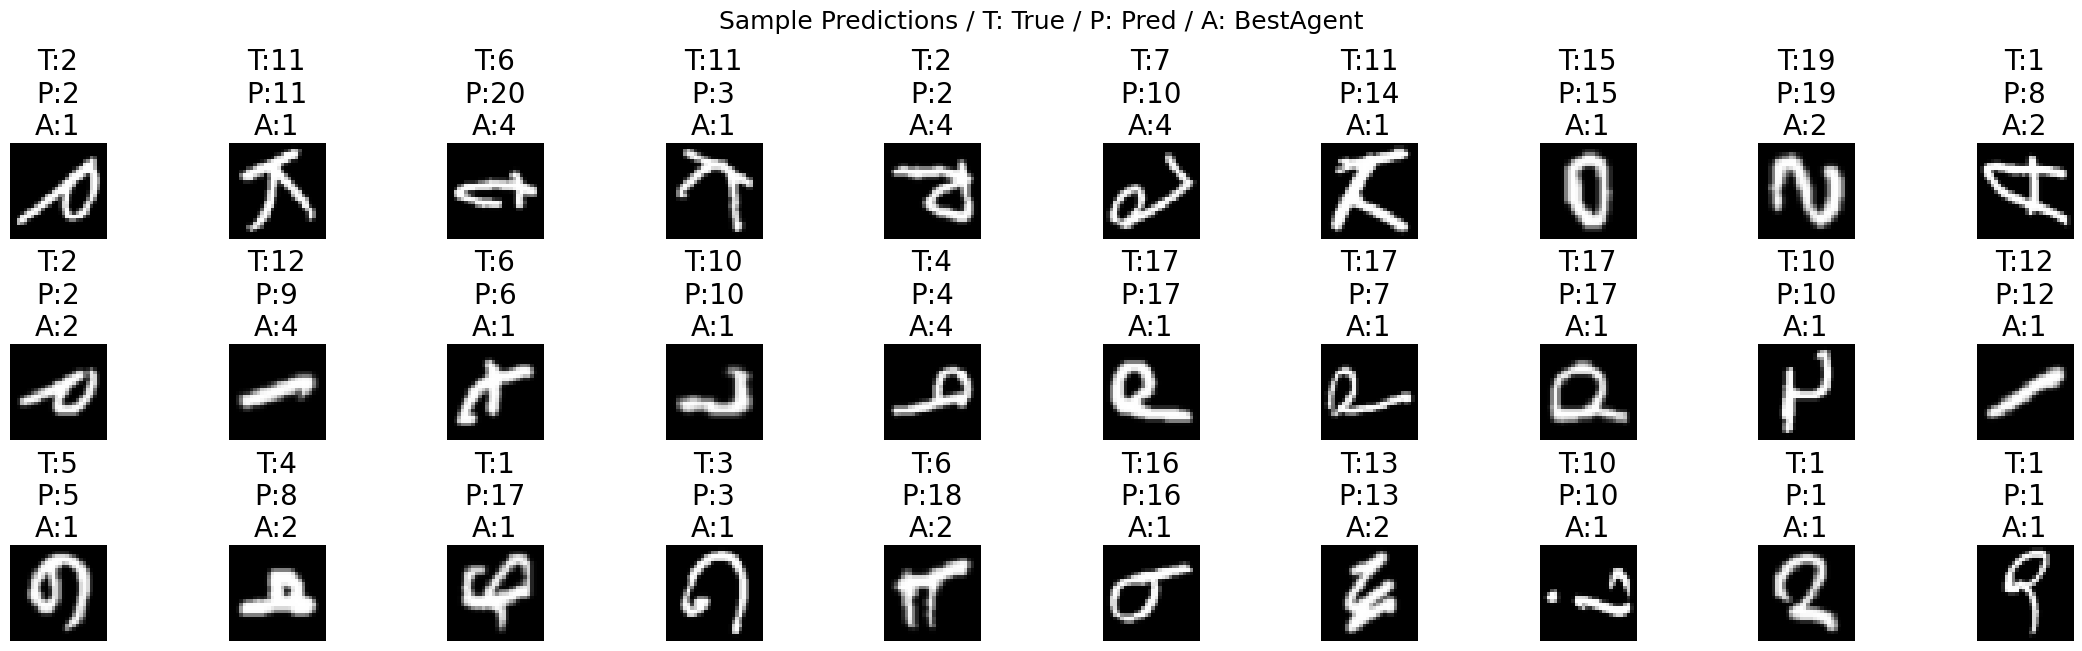

In [ ]:
#CHO_SEOKJIN

import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
import tensorflow_datasets as tfds

class NOC_Agent:
  def __init__(self, model_builder, threshold):
    #Initialize the agent's neural network model using the given builder function
    self.model = model_builder()
    self.threshold = threshold

  def fit(self, X, y, epochs, batch_size):
    #Use a validation split if enough data is provided
    val_split = 0.1 if len(X) >= 10 else 0.0
    self.history = self.model.fit(
      X, y,
      epochs=epochs,
      batch_size=batch_size,
      validation_split=val_split,
      verbose=0
    )

  def predict(self, X):
    probs = self.model.predict(X, verbose=0)
    preds = np.argmax(probs, axis=1)
    #The confidence is the highest probability value for each prediction
    confidences = np.max(probs, axis=1)
    return preds, confidences

"""
Converts a TensorFlow dataset of images and labels to numpy arrays, normalizes the image data to [0,1],
and optionally limits the number of samples.
"""
def preprocess(ds, max_samples):
  images, labels = [], []
  count = 0
  for img, label in tfds.as_numpy(ds):
    if max_samples and count >= max_samples:
      break
    images.append(img.astype(np.float32)/255.0)
    labels.append(label-1) #0~25
    count += 1
  return np.array(images), np.array(labels)

"""
This function downloads the EMNIST Letters dataset using TensorFlow Datasets,
applies preprocessing (normalization, label adjustment), and optionally limits
the number of samples used for training and testing.
"""
def load_emnist(max_train, max_test):
  print(f"Loading EMNIST with max_train={max_train}, max_test={max_test}")
  ds_train = tfds.load('emnist/letters', split='train', as_supervised=True)
  ds_test = tfds.load('emnist/letters', split='test', as_supervised=True)

  X_train, y_train = preprocess(ds_train, max_train)
  X_test, y_test = preprocess(ds_test, max_test)

  #Expand data dimensions (for CNN input compatibility)
  X_train = X_train[..., np.newaxis]
  X_test = X_test[..., np.newaxis]

  print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
  return X_train, y_train, X_test, y_test

"""
The following four functions define the model architectures for each agent.
Each agent uses a different neural network structure. The hyperparameters were tuned
so that all four models achieve comparable performance.
"""
def build_CNN_agent():
  #CNN focusing on spatial features
  model = keras.Sequential([
    keras.layers.Conv2D(16, (3,3), activation='relu', input_shape=(28,28,1)),
    keras.layers.MaxPooling2D(2,2),
    keras.layers.Conv2D(32, (3,3), activation='relu'),
    keras.layers.MaxPooling2D(2,2),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(26, activation='softmax')
  ])
  model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  return model

def build_large_kernel_CNN_agent():
  #Captures global patterns with large convolutional kernels
  model = keras.Sequential([
    keras.layers.Conv2D(8, (7,7), activation='relu', input_shape=(28,28,1)),
    keras.layers.MaxPooling2D(3,3),
    keras.layers.Conv2D(16, (5,5), activation='relu'),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(26, activation='softmax')
  ])
  model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  return model

def build_MLP_agent():
  #Learning global patterns (MLP architecture)
  model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28, 1)),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(26, activation='softmax')
  ])
  model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  return model

def build_regularized_MLP_agent():
  #Strong regularization for better generalization (RMSprop optimizer)
  model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28, 1)),
    keras.layers.Dense(256, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.4),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.4),
    keras.layers.Dense(26, activation='softmax')
  ])
  model.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
  return model

"""
Trains a Novelty-Organizing Classifiers-style multi-agent system on the given dataset.

This function initializes several agents (models) using different architectures,
each agent is first trained on a different portion of the initial data.
Then, the remaining training data is processed in batches:
- Each agent predicts on the batch and samples with high confidence are considered covered.
- For samples that are not confidently classified by any agent, a new agent can be created up to max_agents and trained on those samples.
- If the maximum number of agents is reached, remaining unassigned samples are assigned to the most confident existing agent for additional training.
"""
def noc_train(X_train, y_train, model_builders, init_samples, batch_check, epochs, batch_size, max_agents):
  #NOC-based multi-agent learning
  agents = []
  n_agents = len(model_builders)
  n_init = init_samples // n_agents
  n_train = len(X_train)

  print(f"Initializing {n_agents} agents with {n_init} samples each...")

  #Initial training for each agent with a portion of the data
  for i in range(n_agents):
    print(f"Training initial agent {i+1}/{n_agents}...")
    agent = NOC_Agent(model_builders[i], threshold=0.7)
    X_init = X_train[i*n_init:(i+1)*n_init]
    y_init = y_train[i*n_init:(i+1)*n_init]
    agent.fit(X_init, y_init, epochs, batch_size)
    agents.append(agent)

  ptr = init_samples

  if max_agents is None:
    max_agents = len(model_builders)

  batch_count = 0
  while ptr < n_train:
    batch_count += 1
    end = min(ptr + batch_check, n_train)
    x_batch = X_train[ptr:end]
    y_batch = y_train[ptr:end]

    if batch_count % 10 == 0:
      print(f"Processing batch {batch_count}, samples {ptr}-{end}/{n_train}")

    assigned = np.zeros(len(x_batch), dtype=bool)

    #Vectorized confidence check for each agent
    for agent in agents:
      _, conf = agent.predict(x_batch)
      assigned = assigned | (conf >= agent.threshold)

    #Find samples that are not assigned to any confident agent
    unassigned_idx = np.where(~assigned)[0]

    if len(unassigned_idx) > 0:
      #If possible, create a new agent and train it on unassigned samples
      if len(agents) < max_agents:
        print(f"Creating new agent {len(agents)+1} at batch {batch_count} (threshold=0.7, unassigned: {len(unassigned_idx)})")
        new_agent = NOC_Agent(model_builders[len(agents) % len(model_builders)], threshold=0.7)
        new_agent.fit(x_batch[unassigned_idx], y_batch[unassigned_idx], epochs=epochs, batch_size=batch_size)
        agents.append(new_agent)
      else:
        #If the maximum number of agents is reached, do a small update for the most confident agent
        if len(unassigned_idx) <= 10:  #Only small updates
          confs = np.stack([agent.predict(x_batch[unassigned_idx])[1] for agent in agents], axis=0)
          best_idx = np.argmax(confs, axis=0)
          for i, idx_in_batch in enumerate(unassigned_idx):
            best_agent = agents[best_idx[i]]
            best_agent.fit(x_batch[idx_in_batch:idx_in_batch+1], y_batch[idx_in_batch:idx_in_batch+1], epochs=1, batch_size=1)

    ptr = end

  print(f"Training completed with {len(agents)} agents")
  return agents

#Determine the final prediction by selecting the class of the agent with the highest confidence for each sample (soft voting)
def noc_predict(agents, X):
  all_preds, all_confs = [], []
  for agent in agents:
    preds, confs = agent.predict(X)
    all_preds.append(preds)
    all_confs.append(confs)
  all_preds = np.array(all_preds)
  all_confs = np.array(all_confs)
  best_idx = np.argmax(all_confs, axis=0)
  final_pred = all_preds[best_idx, np.arange(X.shape[0])]
  return final_pred

#Plot Validation Accuracy/Loss for each Agent
def plot_agent_histories(agents):
  plt.figure(figsize=(12, 5))
  # Accuracy
  plt.subplot(1, 2, 1)
  for i, agent in enumerate(agents):
    history = getattr(agent, 'history', None)
    if history and 'val_accuracy' in history.history:
      plt.plot(history.history['val_accuracy'], label=f'Agent {i+1} val_acc')
  plt.xlabel('Epoch')
  plt.ylabel('Validation Accuracy')
  plt.title('Agent-wise Validation Accuracy')
  plt.legend()

  # Loss
  plt.subplot(1, 2, 2)
  for i, agent in enumerate(agents):
    history = getattr(agent, 'history', None)
    if history and 'val_loss' in history.history:
      plt.plot(history.history['val_loss'], label=f'Agent {i+1} val_loss')
  plt.xlabel('Epoch')
  plt.ylabel('Validation Loss')
  plt.title('Agent-wise Validation Loss')
  plt.legend()
  plt.tight_layout()
  plt.show()

#Bar plot of Train/Test Accuracy for each Agent
def plot_individual_agent_train_test_accuracy(agents, X_train, y_train, X_test, y_test):
  train_accs, test_accs = [], []

  #Calculate train and test accuracy for each agent
  for i, agent in enumerate(agents):
    y_pred_train, _ = agent.predict(X_train)  #Predict on train set
    train_acc = np.mean(y_pred_train == y_train)  #Compute train accuracy
    train_accs.append(train_acc)

    y_pred_test, _ = agent.predict(X_test)  #Predict on test set
    test_acc = np.mean(y_pred_test == y_test)  #Compute test accuracy
    test_accs.append(test_acc)

    print(f"Agent {i+1} Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")

  x = np.arange(1, len(agents)+1)
  width = 0.35
  plt.figure(figsize=(8, 5))
  plt.bar(x - width/2, train_accs, width, label="Train Accuracy")
  plt.bar(x + width/2, test_accs, width, label="Test Accuracy")
  plt.xticks(x, [f"Agent {i+1}" for i in range(len(agents))])
  plt.ylim(0, 1)
  plt.ylabel("Accuracy")
  plt.title("Train/Test Accuracy per Agent")
  plt.legend()
  plt.show()

#Visualize example predictions from the test set
def plot_example_predictions(X_test, y_test, y_pred, agents, n=30):
  rows = n // 10 + int(n % 10 != 0) #Calculate the number of rows needed
  plt.figure(figsize=(22, 2.2 * rows))
  idxs = np.random.choice(len(X_test), n, replace=False) #Randomly select n samples from the test set
  for i, idx in enumerate(idxs):
    img = X_test[idx].squeeze()
    true_label = y_test[idx]
    pred_label = y_pred[idx]

    #Get the confidence score from each agent for this image
    confs = [agent.predict(X_test[idx:idx+1])[1][0] for agent in agents]
    best_agent = np.argmax(confs) + 1  #Index of the most confident agent (1-based)

    plt.subplot(rows, 10, i + 1)
    plt.imshow(img, cmap="gray")
    plt.axis("off")
    plt.title(
        f"T:{true_label+1}\nP:{pred_label+1}\nA:{best_agent}",
        fontsize=20
    )
  plt.suptitle("Sample Predictions / T: True / P: Pred / A: BestAgent", fontsize=18)
  plt.tight_layout()
  plt.show()

def main():
  #fix seed
  random.seed(42)
  np.random.seed(42)
  tf.random.set_seed(42)

  #load emnist data
  X_train, y_train, X_test, y_test = load_emnist(max_train=None, max_test=None)

  #Define agent models to be used
  agent_builders = [build_CNN_agent, build_MLP_agent, build_large_kernel_CNN_agent, build_regularized_MLP_agent]

  print("Starting NOC training...")

  #start learning
  agents = noc_train(
    X_train, y_train, agent_builders,
    init_samples=10000,  #Initial training samples
    batch_check=200,     #Batch size for assignment/checking
    epochs=12,           #Number of epochs
    batch_size=64,       #Training batch size
    max_agents=4         #Maximum number of agents
  )

  #visualization (Accuracy, Loss of each agent)
  plot_agent_histories(agents)
  plot_individual_agent_train_test_accuracy(agents, X_train, y_train, X_test, y_test)

  # Predict test set labels using all agents and calculate overall test accuracy
  y_pred = noc_predict(agents, X_test)
  acc = np.mean(y_pred == y_test)
  print("NOC-based Multi-Agent Test Accuracy:", acc)

  #visualization (example predictions)
  plot_example_predictions(X_test, y_test, y_pred, agents)

if __name__ == "__main__":
  main()